## Droplet size analysis

### Import libraries and define functions

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import ptitprince as pt
import seaborn as sns
import pandas as pd
from pandas import DataFrame
import os
%matplotlib inline

def arrange_axis():
    sns.set_style('ticks')
    plt.grid(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().yaxis.set_ticks_position('left')
    plt.gca().xaxis.set_ticks_position('bottom')

### Data processing and merging

In [3]:
# Directories for three independent datasets
dir_a = 'Droplet_size_data/260609 ImageJ/'
dir_b = 'Droplet_size_data/260610_1 ImageJ/'
dir_c = 'Droplet_size_data/260610_2 ImageJ/'
dates_N3 = ['260609', '260610_1', '260610_2']

# Mapping experimental names to conditions
Names = {'#a_0h':'DEX1.5_PEG20k_0h', '#a_2h':'DEX1.5_PEG20k_2h', '#a_4h':'DEX1.5_PEG20k_4h', \
         '#b_0h':'DEX0.75_PEG20k_0h', '#b_2h':'DEX0.75_PEG20k_2h', '#b_4h':'DEX0.75_PEG20k_4h', \
         '#c_0h':'DEX1.5_PEG35k_0h', '#c_2h':'DEX1.5_PEG35k_2h', '#c_4h':'DEX1.5_PEG35k_4h', \
         '#d_0h':'DEX0.75_PEG35k_0h', '#d_2h':'DEX0.75_PEG35k_2h', '#d_4h':'DEX0.75_PEG35k_4h'}

# Data processing
dAlls = []
for j, dir1 in enumerate([dir_a, dir_b, dir_c]):
    samples = sorted(os.listdir(dir1))
    new_ds = []
    date = dates_N3[j]
    for i in range(len(samples)):
        dir2 = dir1 + samples[i]
        files = sorted(os.listdir(dir2 + '/Result'))
        ds_set = [pd.read_csv(dir2 + '/Result/' + f) for f in files]
        Ls = [len(d) for d in ds_set]
        # Retain the FITC-channel measurements (second half of each ImageJ results file)
        ds_set2 = [d[int(0.5*L):] for d,L in zip(ds_set, Ls)] 
        # Combine
        d = pd.concat(ds_set2).reset_index()
        # Original file names
        original_files = np.hstack([[f]*len(d) for f,d in zip(files, ds_set2)])
        # Calculate equivalent diameters and spherical volumes
        Area = np.array(d['Area'])
        Diameter = np.sqrt(Area/np.pi)*2
        Radius = 0.5*Diameter
        Volume = (4/3)*np.pi*(Radius**3)
        # Fluorescence intensity (FITC) and circularity
        Mean = np.array(d['Mean'])
        Circ = np.array(d['Circ.'])
        # Sample names and dates
        sample_names = [samples[i]]*len(d)
        sample_series = [Names[samples[i]]]*len(d)
        dates = [date]*len(d)
        # Create DataFrame
        d2 = DataFrame(np.vstack([Area, Radius, Diameter, Volume, Mean, Circ, sample_names, original_files, sample_series, dates]).T, \
                        columns=['Area', 'Radius (um)', 'Diameter (um)', 'Volume (fL)', 'FITC', 'Circularity', 'Name', 'Source', 'Series', 'Date'])
        new_ds.append(d2)
    d_N = pd.concat(new_ds)
    d_N.to_csv('Droplet_size_data/' +date+ '_merged.csv', index=False)
    dAlls.append(d_N)
dAll = pd.concat(dAlls)
dAll.to_csv('Droplet_size_data/droplet_size_N3_merged.csv', index=False)

### Data filtering and subsampling

In [5]:
file = 'Droplet_size_data/droplet_size_N3_merged.csv'
dAll = pd.read_csv(file)
dates = ['260609', '260610_1', '260610_2']
Series = ['DEX1.5_PEG20k_0h', 'DEX1.5_PEG20k_2h', 'DEX1.5_PEG20k_4h', \
          'DEX1.5_PEG35k_0h', 'DEX1.5_PEG35k_2h', 'DEX1.5_PEG35k_4h',\
          'DEX0.75_PEG20k_0h', 'DEX0.75_PEG20k_2h', 'DEX0.75_PEG20k_4h',\
          'DEX0.75_PEG35k_0h', 'DEX0.75_PEG35k_2h', 'DEX0.75_PEG35k_4h']

# Split data by experimental condition
ds = [dAll[dAll['Series']==S].reset_index(drop=True) for S in Series]

# Retain droplets with circularity > 0.9
ds2 = [d[d['Circularity']>0.9] for d in ds]

# Retain the brightest 50% of droplets based on FITC-labeled DEX fluorescence 
# and randomly sample up to 300 droplets from each independent experiment
N = 300
ds_dates = []
for d in ds2:
    ds_sub = []
    for date in dates:
        d_date = d[d['Date'] == date]
        d_top = d_date.sort_values('FITC', ascending=False)[:int(len(d_date)*0.5)]
        ds_sub.append(d_top.sample(n=min(N, len(d_top)), random_state=0))
    ds_dates.append(ds_sub)

# Number of droplets retained for each condition and independent experiment
print('count_FITC',[[len(d[0]),len(d[1]),len(d[2])] for d in ds_dates])

d_plot = pd.concat([pd.concat(ds) for ds in ds_dates])

# Mean diameters
for S in Series:
    mean_diameter = np.mean(d_plot[d_plot['Series']==S]['Diameter (um)'])
    print(S, mean_diameter)

count_FITC [[300, 300, 300], [300, 300, 300], [221, 233, 300], [300, 300, 300], [300, 300, 300], [300, 300, 300], [300, 300, 300], [300, 300, 300], [300, 300, 300], [300, 300, 300], [300, 300, 300], [300, 300, 300]]
DEX1.5_PEG20k_0h 6.6720606673343985
DEX1.5_PEG20k_2h 7.9948277703876895
DEX1.5_PEG20k_4h 9.988020691609464
DEX1.5_PEG35k_0h 6.144011719721331
DEX1.5_PEG35k_2h 6.879709037449586
DEX1.5_PEG35k_4h 7.962793237158609
DEX0.75_PEG20k_0h 3.694287009667384
DEX0.75_PEG20k_2h 5.038044066760053
DEX0.75_PEG20k_4h 5.85593703357088
DEX0.75_PEG35k_0h 3.7195134437627893
DEX0.75_PEG35k_2h 4.808223023469178
DEX0.75_PEG35k_4h 5.292519267216912


### Visualization

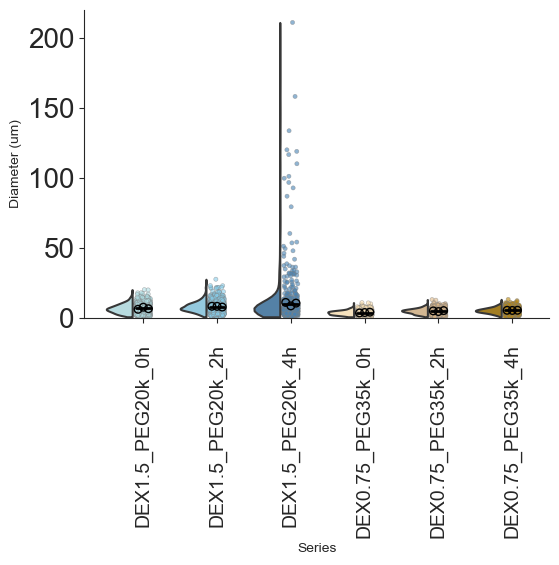

In [16]:
palette = {'DEX1.5_PEG20k_0h': 'powderblue', 'DEX1.5_PEG20k_2h': 'skyblue', 'DEX1.5_PEG20k_4h':'steelblue', \
          'DEX1.5_PEG35k_0h': '#D2EEDF', 'DEX1.5_PEG35k_2h': 'mediumaquamarine', 'DEX1.5_PEG35k_4h': 'seagreen',\
          'DEX0.75_PEG20k_0h': 'thistle', 'DEX0.75_PEG20k_2h': 'plum', 'DEX0.75_PEG20k_4h': 'mediumorchid',\
          'DEX0.75_PEG35k_0h': 'moccasin', 'DEX0.75_PEG35k_2h': 'burlywood', 'DEX0.75_PEG35k_4h': 'darkgoldenrod'}

Series2 = ['DEX1.5_PEG20k_0h', 'DEX1.5_PEG20k_2h', 'DEX1.5_PEG20k_4h', \
          'DEX0.75_PEG35k_0h', 'DEX0.75_PEG35k_2h', 'DEX0.75_PEG35k_4h']

d_plot2 = d_plot[d_plot['Series'].isin(Series2)]

Which = 'Part' # 'All': all conditions; 'Part': selected conditions
Size = 'large' # 'small' or 'large' (y-axis range only)

if Which == 'All':
    dp = d_plot.copy()
    fig, ax = plt.subplots(1, 1, figsize=(12,4))
    Ser = Series.copy()
elif Which == 'Part':
    dp = d_plot2.copy()
    fig, ax = plt.subplots(1, 1, figsize=(6,4))
    Ser = Series2.copy()

key = 'Diameter (um)'
dates = ['260609', '260610_1', '260610_2']

# Distribution of individual droplets
ax = pt.half_violinplot(data=dp, x='Series', y=key, order=Ser, palette=palette, hue='Series', width=0.7,
                       inner=None, cut=0, linewidth=1.5, bw=0.3)

# Individual droplets from each independent experiment
for date in dates:
    ax = sns.stripplot(data=dp[dp['Date']==date], x="Series", y=key, zorder=0, order=Ser,\
                       hue = 'Series', palette=palette, size=3, jitter=0.1, alpha=0.6, edgecolor='grey', linewidth=0.4)

# Mean diameter for each independent experiment
means_date = []
for date in dates:
    d = dp[dp['Date']==date]
    means = [np.average(d[d['Series']==S][key]) for S in Ser]
    means_date.append(means)
L = len(Ser)
ax.scatter(np.arange(L)-0.07, means_date[0], facecolors='none', edgecolor="black", lw = 1, s = 30)
ax.scatter(np.arange(L), means_date[1], facecolors='none', edgecolor="black", lw = 1, s = 30)
ax.scatter(np.arange(L)+0.07, means_date[2], facecolors='none', edgecolor="black", lw = 1, s = 30)

# Mean across the three independent experiments
for i in range(L):
    m = np.mean(np.array(means_date)[:,i])
    ax.plot([i-0.1,i+0.1], [m,m], 'k', lw=2)

ax.get_legend().remove()
ax.set_xlim(-0.8,)
ax.tick_params(axis='x', pad=15)
ax.tick_params(axis ='x',labelsize =14), ax.tick_params(axis ='y',labelsize =18)
if Size == 'small':
    ax.set_ylim(0,40)
elif Size == 'large':
    ax.set_ylim(0,220)
    ax.tick_params(axis ='y',labelsize =20)

plt.xticks(rotation=90)
arrange_axis()
fig.savefig('Droplet_size_data/Figs/Size_distribution_'+Which+'_'+Size+'.svg', bbox_inches='tight')
plt.show()